In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, LSTM, Dense, Flatten, Conv2D, MaxPooling2D, Dropout
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.layers import Reshape
import matplotlib.pyplot as plt

In [ ]:
# Step 1: Load and preprocess MNIST dataset
(x_train, y_train), (x_test, y_test) = mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
# Normalize pixel values
x_train = x_train / 255.0
x_test = x_test / 255.0

# Convert labels to one-hot encoding
y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

In [ ]:
# Character Recognition using RNN (LSTM-based)

# Reshape each image (28x28) as a sequence of 28 time steps with 28 features each
x_train_rnn = x_train.reshape((x_train.shape[0], 28, 28))
x_test_rnn = x_test.reshape((x_test.shape[0], 28, 28))

# Define RNN model
rnn_model = Sequential([
    LSTM(128, input_shape=(28, 28)),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])

rnn_model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
print("\nTraining RNN model...")
history_rnn = rnn_model.fit(x_train_rnn, y_train, epochs=3, batch_size=128, validation_data=(x_test_rnn, y_test))

# Evaluate RNN
rnn_loss, rnn_acc = rnn_model.evaluate(x_test_rnn, y_test)
print(f"\nRNN Test Accuracy: {rnn_acc:.4f}")

/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)



Training RNN model...
Epoch 1/3
469/469 ━━━━━━━━━━━━━━━━━━━━ 41s 82ms/step - accuracy: 0.6461 - loss: 1.0182 - val_accuracy: 0.9433 - val_loss: 0.1887
Epoch 2/3
469/469 ━━━━━━━━━━━━━━━━━━━━ 38s 80ms/step - accuracy: 0.9494 - loss: 0.1672 - val_accuracy: 0.9663 - val_loss: 0.1131
Epoch 3/3
469/469 ━━━━━━━━━━━━━━━━━━━━ 39s 83ms/step - accuracy: 0.9678 - loss: 0.1044 - val_accuracy: 0.9716 - val_loss: 0.0929
313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step - accuracy: 0.9647 - loss: 0.1084

RNN Test Accuracy: 0.9716


In [ ]:
# Character Recognition using CNN

# Reshape for CNN input (add channel dimension)
x_train_cnn = x_train.reshape((x_train.shape[0], 28, 28, 1))
x_test_cnn = x_test.reshape((x_test.shape[0], 28, 28, 1))

# Define CNN model
cnn_model = Sequential([
    Conv2D(32, (3,3), activation='relu', input_shape=(28,28,1)),
    MaxPooling2D((2,2)),
    Conv2D(64, (3,3), activation='relu'),
    MaxPooling2D((2,2)),
    Flatten(),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])

cnn_model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
print("\nTraining CNN model...")
history_cnn = cnn_model.fit(x_train_cnn, y_train, epochs=3, batch_size=128, validation_data=(x_test_cnn, y_test))

# Evaluate CNN
cnn_loss, cnn_acc = cnn_model.evaluate(x_test_cnn, y_test)
print(f"\nCNN Test Accuracy: {cnn_acc:.4f}")

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)



Training CNN model...
Epoch 1/3
469/469 ━━━━━━━━━━━━━━━━━━━━ 51s 104ms/step - accuracy: 0.8478 - loss: 0.5333 - val_accuracy: 0.9779 - val_loss: 0.0713
Epoch 2/3
469/469 ━━━━━━━━━━━━━━━━━━━━ 47s 100ms/step - accuracy: 0.9778 - loss: 0.0711 - val_accuracy: 0.9815 - val_loss: 0.0530
Epoch 3/3
469/469 ━━━━━━━━━━━━━━━━━━━━ 48s 102ms/step - accuracy: 0.9848 - loss: 0.0477 - val_accuracy: 0.9855 - val_loss: 0.0422
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.9813 - loss: 0.0506

CNN Test Accuracy: 0.9855


In [ ]:
# Comparison Results

print("\n*************** COMPARISON ************")
print(f"RNN (LSTM) Accuracy: {rnn_acc:.4f}")
print(f"CNN Accuracy:       {cnn_acc:.4f}")

if cnn_acc > rnn_acc:
    print("CNN performs better because it captures spatial patterns in images.")
else:
    print("RNN performs better, possibly due to temporal-like pattern interpretation.")


*************** COMPARISON ************
RNN (LSTM) Accuracy: 0.9716
CNN Accuracy:       0.9855
CNN performs better because it captures spatial patterns in images.


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 112ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step


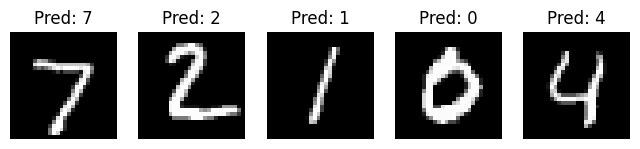

In [ ]:
# Visualize some predictions

plt.figure(figsize=(8, 3))
for i in range(5):
    plt.subplot(1, 5, i+1)
    plt.imshow(x_test[i].reshape(28,28), cmap='gray')
    plt.axis('off')
    pred = np.argmax(cnn_model.predict(x_test_cnn[i].reshape(1,28,28,1)))
    plt.title(f"Pred: {pred}")
plt.show()

### Introduction

A Recurrent Neural Network (RNN) is a type of artificial neural network designed to recognize patterns in sequential data — such as time series, text, speech, and handwriting.  

Unlike traditional feedforward neural networks, which assume all inputs and outputs are independent, RNNs have loops that allow information to persist over time.

### Why RNN?

Traditional neural networks treat each input independently, so they cannot understand sequences.  

RNNs solve this by using feedback connections, allowing information from earlier steps to influence later ones.

### Example:
To predict the next word in “I love deep ____”,  

RNN considers the context (“I love deep”) instead of treating each word separately.

### RNN Structure

An RNN processes input one step at a time and keeps track of what it has seen before using a hidden state.  

x1 → [RNN cell] → h1 → [RNN cell] → h2 → [RNN cell] → h3

Where:

x₁, x₂, x₃ = Input sequence (words, time steps, etc.)

h₁, h₂, h₃ = Hidden states (memory of past information)

y₁, y₂, y₃ = Outputs  

Each RNN cell takes two inputs:

1. The current input (xₜ)

2. The previous hidden state (hₜ₋₁)

and produces two outputs:

1. A new hidden state (hₜ)

2. A prediction/output (yₜ)
  

### Types of RNNs

Simple RNN: The basic form, suitable for short sequences.

LSTM (Long Short-Term Memory): Handles long-term dependencies by using gates (forget, input, output).

GRU (Gated Recurrent Unit): A simplified LSTM with fewer gates and faster computation.  

### Advantages

Maintains memory of previous inputs
Handles sequential/temporal data naturally
Can process inputs of variable length  

### Limitations

Difficult to remember long-term dependencies (older information fades away).

Suffers from vanishing and exploding gradient problems during training.

Training is slow due to sequential processing.  

### Example (Character Recognition)

In character recognition, RNN can be used to process an image row by row — treating each row as a sequence step.
The model learns how each row contributes to identifying a particular character, maintaining context across rows.

## Simple RNN Example in Keras

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Embedding, Dense

model = Sequential([
    Embedding(input_dim=10000, output_dim=32, input_length=100),
    SimpleRNN(32),
    Dense(1, activation='sigmoid')
])

model.summary()


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)